In [51]:
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.covariance import MinCovDet
import h5py
import json

def sklearn_cov(X):
    mcd = MinCovDet().fit(X)
    n_flagged = (~mcd.support_).sum()
    print(f"{n_flagged} / {len(mcd.support_)} samples flagged as outliers")
    cov = mcd.covariance_        # shape (n_freq, n_freq), robust to RFI outliers
    off_diag = cov - np.diag(np.diag(cov))
    p = cov.shape[0]
    mean_off_diag = np.abs(off_diag).sum() / (p * (p - 1))   # divide by count of off-diagonal entries
    mean_diag = np.abs(np.diag(cov)).mean()
    ratio = mean_off_diag / mean_diag
    plt.imshow(cov)
    print(ratio)
    
def np_cov(X):
    cov = np.cov(X.T)   # noise_data shape (n_freq, n_time); np.cov treats rows as variables by default,
                            # so no transpose needed here (unlike sklearn's (n_samples, n_features) convention)

    off_diag = cov - np.diag(np.diag(cov))
    p = cov.shape[0]
    mean_off_diag = np.abs(off_diag).sum() / (p * (p - 1))
    mean_diag = np.abs(np.diag(cov)).mean()
    ratio = mean_off_diag / mean_diag
    print(ratio)

# Baseband data

In [5]:
data = np.load('event_22154974_BB.npz')
power, freq, time = data['power'], data['freq'], data['time']
freq = freq[::-1]
power = power[::-1, :]

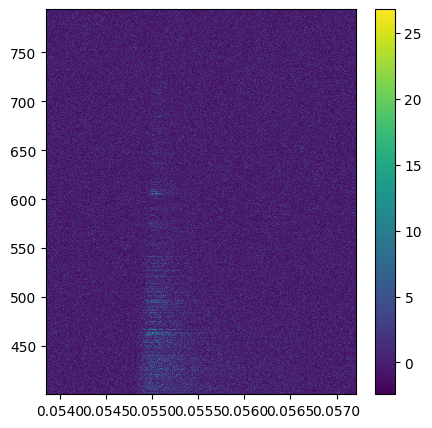

In [9]:
fig = plt.figure(figsize=(5, 5))
img = plt.imshow(power,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

Noise segments we will draw from


Text(0, 0.5, 'Frequency [MHz]')

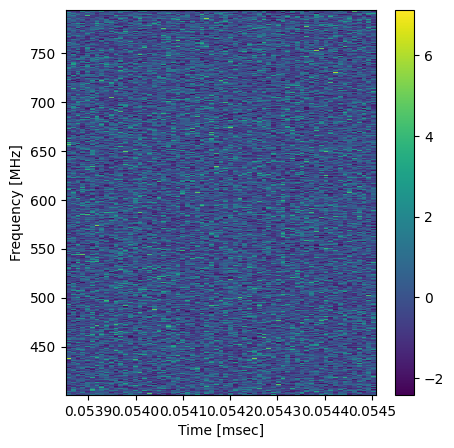

In [40]:
time_array = np.asarray(time, dtype=np.float32)[None, :]
data_reshaped = power
freq_array_reshaped = np.asarray(freq, dtype=np.float32)[:, None]
times_noise = np.asarray(time_array[0][0:int(len(time_array[0])/5)])
noise_data = data_reshaped[:,0:len(times_noise)]
print("Noise segments we will draw from")
fig = plt.figure(figsize=(5, 5))
img = plt.imshow(noise_data,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(times_noise[0], times_noise[-1], freq[0], freq[-1]))
plt.colorbar(img)

plt.xlabel("Time [msec]")
plt.ylabel("Frequency [MHz]")

### frequency covariance

SKLearn covariance


/opt/pysetup/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-25764.469110038229701 > -25766.820103167916386). You may want to try with a higher value of support_fraction (current value: 1.000).
  warnings.warn(
/opt/pysetup/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-25769.734124586935650 > -25770.085868911195575). You may want to try with a higher value of support_fraction (current value: 1.000).
  warnings.warn(
/opt/pysetup/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-25763.672902104899549 > -25768.228872653282451). You may want to try with a higher value of support_fraction (current value:

0 / 65 samples flagged as outliers
0.09897604790432891
Numpy covariance
0.09897604790432893


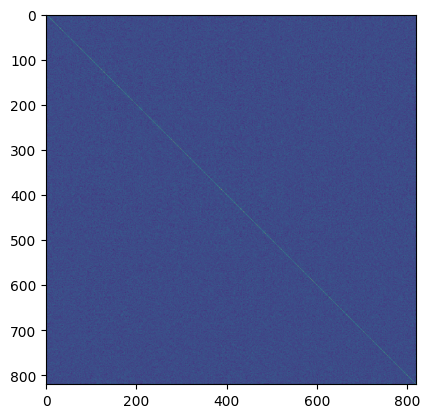

In [47]:
print("SKLearn covariance")
sklearn_cov(noise_data.T)
print("Numpy covariance")
np_cov(noise_data.T)

## time covariance

SKLearn covariance
237 / 820 samples flagged as outliers
0.03529958934110017
Numpy covariance
0.027840249068952827


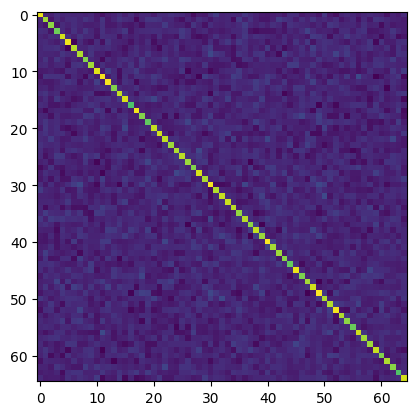

In [46]:
print("SKLearn covariance")
sklearn_cov(noise_data)
print("Numpy covariance")
np_cov(noise_data)

# Intensity data

In [59]:
filename = "FRB20190713B_stokesi_dynamic_spectrum.h5"

with h5py.File(filename, "r") as handler:

    print(handler.attrs.keys())
    
    event_id = handler.attrs["event_id"]
    freq = handler["index_map"]["freqs"][:]
    
    toa = json.loads(handler.attrs["burst_parameters_json"])["arrival_time"]
    time = (handler["index_map"]["times"][:] - np.mean(toa))

    good_freq = handler["good_freq"][:]
    flag = handler["flag"][:]
        
    data = handler["data"][:]
    
    print(handler.attrs["burst_parameters_json"])

<KeysViewHDF5 ['beam_number', 'burst_parameters_json', 'catalog', 'center_time', 'contact', 'creator', 'datatype', 'dm_const', 'dm_incoherent', 'dm_index', 'doi', 'event_id', 'freqs_bin0', 'instrument', 'is_dedispersed', 'num_freq', 'num_time', 'pipeline_parameters_json', 'pulse_emission_region', 'ref_freq', 'repeater_name', 'res_freq', 'res_time', 'start_time_unix_nano', 'stokes', 'telescope', 'times_bin0', 'tns_name', 'unwindowed_num_time', 'unwindowed_times_bin0']>
{"amplitude": [-6.845407064242668], "arrival_time": [252543.6388517829], "burst_width": [0.000352764237316877], "dm": [416.0573947085782], "dm_index": [-2.0], "scattering_timescale": [0.0], "scattering_index": [-4.0], "spectral_index": [128.05542297060848], "spectral_running": [-302.85994004409446], "ref_freq": [400.1953125]}


In [60]:
def bin_freq_channels(data, fbin_factor=4):
    num_chan = data.shape[0]
    if num_chan % fbin_factor != 0:
        raise ValueError("frequency binning factor `fbin_factor` should be even")
    data = np.nanmean(data.reshape((num_chan // fbin_factor, fbin_factor) + data.shape[1:]), axis=1)
    return data


def bin_freq_boolean(arr, fbin_factor=4):
    n = arr.shape[0]
    if n % fbin_factor != 0:
        raise ValueError("frequency binning factor must divide number of channels")

    arr = arr.reshape((n // fbin_factor, fbin_factor) + arr.shape[1:])
    return np.any(arr, axis=1)

binning_factor = 2**4
flag = bin_freq_boolean(flag, fbin_factor=binning_factor)
good_freq = bin_freq_boolean(good_freq, fbin_factor=binning_factor)
data = bin_freq_channels(data, fbin_factor=binning_factor)

combined_flag = flag & good_freq[:, np.newaxis]

def additional_flagging(data, good_freq, threshold=0.4):
    """Flag channels whose max value (over time) exceeds threshold,
    considering only currently-good channels."""
    good_idx = np.where(good_freq)[0]              # true channel indices
    row_max = np.max(data[good_idx, :], axis=1)     # peak per good channel
    good_freq[good_idx[row_max > threshold]] = False
    return good_freq

good_freq = additional_flagging(data, good_freq) 
mask_matrix = np.repeat(good_freq[None, :], data.shape[1], axis=0)
mask_matrix=mask_matrix.T
freq_array = np.linspace(freq[0],freq[-1],data.shape[0], dtype=np.float32)[:, None]  # (nfreq,1), MHz
freq_array_reshaped = freq_array[good_freq]

time_array = np.linspace(time[0],time[-1], data.shape[1], dtype=np.float32)[None, :]

data_reshaped = data[mask_matrix].reshape(freq_array_reshaped.shape[0],time_array.shape[1])

First plotting data with masked channels included
Then plotting data with masked channels removed


Text(0, 0.5, 'Frequency [MHz]')

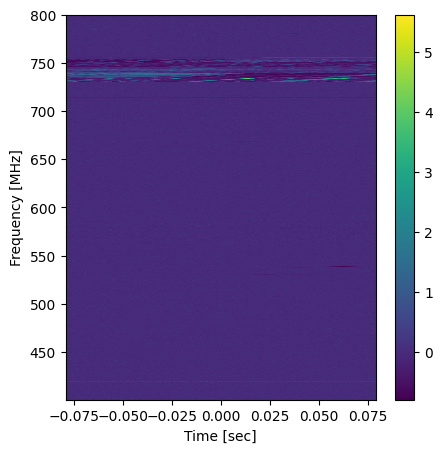

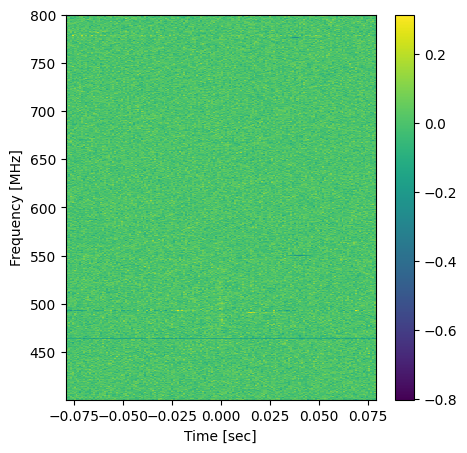

In [62]:
print("First plotting data with masked channels included")

fig = plt.figure(figsize=(5, 5))
img = plt.imshow(data,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

# plt.xlabel("Time [msec]")
plt.xlabel("Time [sec]")
plt.ylabel("Frequency [MHz]")

print("Then plotting data with masked channels removed")

fig = plt.figure(figsize=(5, 5))
img = plt.imshow(data_reshaped,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

# plt.xlabel("Time [msec]")
plt.xlabel("Time [sec]")
plt.ylabel("Frequency [MHz]")

In [64]:
times_noise = np.asarray([i for i in time_array[0] if i<-10/1000]).flatten()
noise_data = data_reshaped[:,0:len(times_noise)]

SKLearn covariance


/opt/pysetup/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:793: UserWarning: The covariance matrix associated to your dataset is not full rank
  warnings.warn(
/opt/pysetup/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-30616.542512716816418 > -30618.847423002931464). You may want to try with a higher value of support_fraction (current value: 1.000).
  warnings.warn(
/opt/pysetup/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-30616.815073224763182 > -30619.786805066902161). You may want to try with a higher value of support_fraction (current value: 1.000).
  warnings.warn(
/opt/pysetup/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:188: RuntimeWarning: Determinant has 

0 / 71 samples flagged as outliers
0.09410254965723379
Numpy covariance
0.09410254965723376


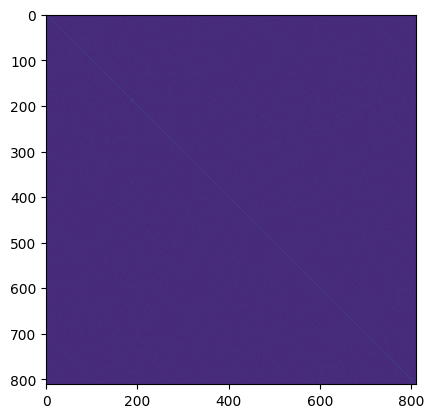

In [65]:
print("SKLearn covariance")
sklearn_cov(noise_data.T)
print("Numpy covariance")
np_cov(noise_data.T)